# 01 — Classificatore a feature sul dataset pulito

Primo classificatore sulle tre versioni del dataset pulito (cartella `1-data-cleaning`, notebook 02):

| versione | regola |
|---|---|
| `min0` | tutte le testate rimaste dopo la pulizia |
| `min10` | solo testate con almeno 10 articoli |
| `min20` | solo testate con almeno 20 articoli |

Classificatore: **TF-IDF + regressione logistica**, lo stesso della prova sul dataset grezzo.
Metriche per articolo e per testata (voto di maggioranza): accuracy, F1 macro, tolerant accuracy ($\alpha$ = 0,5 e 1).

I fold vengono creati qui **una volta sola** e salvati, così i transformer useranno esattamente gli stessi.

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from comune import (PULITO, RESULTS, SEED, LIVELLI, VERSIONI, carica_versione,
                    classificatore_cv, per_testata, tabella_per_fold)

## 1. I fold

Due modi di dividere le testate in 5 fold, mantenendo in ogni fold proporzioni di livelli simili (seed 42):

- **per gruppo** (`fold_gruppo`): ogni gruppo di testate parenti sta tutto in un fold. È il protocollo principale:
  nessuna testata ha sorelle nel training.
- **per testata** (`fold_testata`): ogni testata sta tutta in un fold, ma le sorelle possono finire in fold diversi.
  È il protocollo del paper; lo teniamo solo per confronto.

In [2]:
for nome, file in VERSIONI.items():
    df = pd.read_csv(PULITO + f"dataset_{file}.csv")
    testate = df.groupby("domain").agg(label=("label", "first"), gruppo=("gruppo", "first")).sort_index()

    testate["fold_gruppo"] = 0
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (_, idx) in enumerate(sgkf.split(testate.index, testate.label, groups=testate.gruppo), start=1):
        testate.iloc[idx, testate.columns.get_loc("fold_gruppo")] = fold

    testate["fold_testata"] = 0
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (_, idx) in enumerate(skf.split(testate.index, testate.label), start=1):
        testate.iloc[idx, testate.columns.get_loc("fold_testata")] = fold

    testate[["fold_gruppo", "fold_testata"]].to_csv(PULITO + f"fold_{file}.csv")
    print(f"{nome} ({file}): testate per fold (per gruppo) e livello")
    display(pd.crosstab(testate.fold_gruppo, testate.label.map(lambda k: LIVELLI[k]), margins=True, margins_name="totale"))

nessun minimo (min0): testate per fold (per gruppo) e livello


label,l1,l2,l3,l4,l5,totale
fold_gruppo,,,,,,
1,5,13,42,17,7,84
2,5,14,13,18,7,57
3,131,13,13,17,7,181
4,5,13,13,18,7,56
5,6,13,14,18,7,58
totale,152,66,95,88,35,436


almeno 10 articoli (min10): testate per fold (per gruppo) e livello


label,l1,l2,l3,l4,l5,totale
fold_gruppo,,,,,,
1,98,11,11,14,5,139
2,5,11,42,14,6,78
3,5,13,11,15,6,50
4,5,11,12,15,6,49
5,5,11,12,15,6,49
totale,118,57,88,73,29,365


almeno 20 articoli (min20): testate per fold (per gruppo) e livello


label,l1,l2,l3,l4,l5,totale
fold_gruppo,,,,,,
1,25,7,9,12,5,58
2,4,8,9,13,6,40
3,3,7,42,12,5,69
4,3,9,9,13,6,40
5,4,7,9,13,6,39
totale,39,38,78,63,28,246


**Attenzione al gruppo più grande** (la rete di siti $l_1$): con i fold per gruppo finisce tutto in un fold.
Quando quel fold è il test, nel training restano poche testate $l_1$, e il risultato su $l_1$ dipende anche da questo.
Per questo più sotto riportiamo i risultati anche separando le testate **nei gruppi** da quelle **indipendenti**.

## 2. Addestramento

Per ogni versione e per ogni modo di dividere i fold: 5 addestramenti, ognuno valutato sul fold escluso.

In [3]:
predizioni = {}
for nome, file in VERSIONI.items():
    df = carica_versione(file)
    for schema in ["fold_gruppo", "fold_testata"]:
        inizio = time.time()
        pred = classificatore_cv(df, colonna_fold=schema)
        predizioni[(file, schema)] = pd.DataFrame({
            "article_id": df.article_id, "domain": df.domain, "gruppo": df.gruppo,
            "fold": df[schema], "y_true": df.label, "y_pred": pred})
        print(f"{file:6s} {schema:13s} fatto in {time.time() - inizio:.0f} s")

min0   fold_gruppo   fatto in 345 s


min0   fold_testata  fatto in 782 s


min10  fold_gruppo   fatto in 394 s


min10  fold_testata  fatto in 322 s


min20  fold_gruppo   fatto in 281 s


min20  fold_testata  fatto in 393 s


## 3. Risultati

Media sui 5 fold. Le righe in **grassetto** sono il protocollo principale (fold per gruppo).

In [4]:
righe = []
for (file, schema), art in predizioni.items():
    pub = per_testata(art)
    for livello, dati in [("articoli", art), ("testate", pub)]:
        righe.append({"versione": file, "fold": "per gruppo" if schema == "fold_gruppo" else "per testata",
                      "livello di valutazione": livello, **tabella_per_fold(dati).loc["media"]})
risultati = pd.DataFrame(righe).set_index(["livello di valutazione", "versione", "fold"]).sort_index()

print("PER TESTATA (voto di maggioranza)")
display(risultati.loc["testate"])
print("PER ARTICOLO")
display(risultati.loc["articoli"])

PER TESTATA (voto di maggioranza)


Accuracy  F1 macro  Tolerant α=0.5  Tolerant α=1.0
versione fold                                                           
min0     per gruppo      0.400     0.327           0.533           0.666
         per testata     0.645     0.531           0.747           0.849
min10    per gruppo      0.424     0.367           0.555           0.686
         per testata     0.663     0.571           0.760           0.858
min20    per gruppo      0.453     0.361           0.587           0.721
         per testata     0.561     0.503           0.687           0.813

PER ARTICOLO


Accuracy  F1 macro  Tolerant α=0.5  Tolerant α=1.0
versione fold                                                           
min0     per gruppo      0.389     0.306           0.540           0.692
         per testata     0.489     0.456           0.629           0.769
min10    per gruppo      0.397     0.309           0.544           0.691
         per testata     0.492     0.468           0.627           0.762
min20    per gruppo      0.404     0.301           0.558           0.712
         per testata     0.442     0.401           0.597           0.752

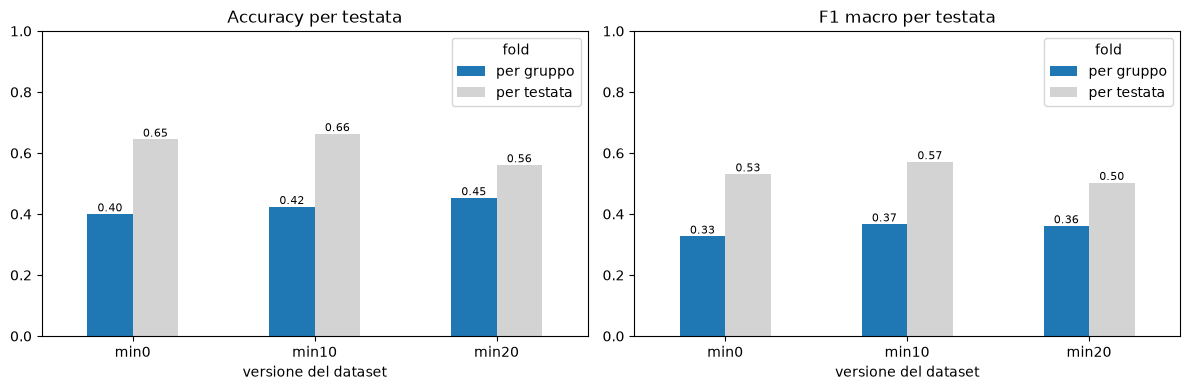

In [5]:
fig, assi = plt.subplots(1, 2, figsize=(12, 4))
for asse, metrica in zip(assi, ["Accuracy", "F1 macro"]):
    tabella = risultati.loc["testate"][metrica].unstack("fold")[["per gruppo", "per testata"]]
    tabella.plot.bar(ax=asse, rot=0, color=["tab:blue", "lightgray"])
    asse.set_title(f"{metrica} per testata")
    asse.set_ylim(0, 1)
    asse.set_xlabel("versione del dataset")
    for contenitore in asse.containers:
        asse.bar_label(contenitore, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Per livello, nei gruppi e fuori

Accuratezza per testata con i **fold per gruppo**, livello per livello. Tra parentesi il numero di testate.

In [6]:
righe = []
for file in VERSIONI.values():
    pub = per_testata(predizioni[(file, "fold_gruppo")])
    gruppo_testata = predizioni[(file, "fold_gruppo")].groupby("domain").gruppo.first()
    dimensione = gruppo_testata.map(gruppo_testata.value_counts())
    pub["tipo"] = pub.domain.map(dimensione).ge(2).map({True: "nei gruppi", False: "indipendenti"})
    pub["giusta"] = pub.y_true == pub.y_pred
    for (liv, tipo), g in pub.groupby(["y_true", "tipo"]):
        righe.append({"versione": file, "livello": LIVELLI[liv], "testate": tipo, "valore": f"{g.giusta.mean():.2f} ({len(g)})"})
    for tipo, g in pub.groupby("tipo"):
        righe.append({"versione": file, "livello": "tutti", "testate": tipo, "valore": f"{g.giusta.mean():.2f} ({len(g)})"})
pd.DataFrame(righe).pivot(index=["livello", "testate"], columns="versione", values="valore")[list(VERSIONI.values())]

versione                    min0       min10       min20
livello testate                                         
l1      indipendenti   0.11 (18)   0.18 (17)   0.18 (11)
        nei gruppi    0.01 (134)  0.00 (101)   0.00 (28)
l2      indipendenti   0.64 (42)   0.66 (35)   0.62 (21)
        nei gruppi     0.54 (24)   0.55 (22)   0.47 (17)
l3      indipendenti   0.26 (39)   0.27 (33)   0.29 (24)
        nei gruppi     0.88 (56)   0.89 (55)   0.89 (54)
l4      indipendenti   0.57 (72)   0.59 (64)   0.60 (55)
        nei gruppi     0.25 (16)    0.11 (9)    0.12 (8)
l5      indipendenti   0.12 (32)   0.19 (26)   0.24 (25)
        nei gruppi      0.00 (3)    0.00 (3)    0.00 (3)
tutti   indipendenti  0.41 (203)  0.45 (175)  0.45 (136)
        nei gruppi    0.29 (233)  0.33 (190)  0.52 (110)

## 5. Salvataggio

In [7]:
for (file, schema), art in predizioni.items():
    art.to_csv(RESULTS + f"01_tfidf_{file}_{schema}_articoli.csv", index=False)
risultati.to_csv(RESULTS + "01_tfidf_metriche.csv")
print("Salvato in", RESULTS)

Salvato in ../Results/2-classificazione/
